# Exercise 2

In [49]:


import matplotlib.pyplot as plt
import numpy as np

## Adaline training function

In [50]:
def fit_adaline(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    n_samples, n_features = X.shape

    # add theta weight
    X_ext = np.c_[np.ones(n_samples), X]

    # Adaptive learning rate based on feature scale if not explicitly provided
    mean_sq_norm = np.mean(np.sum(X_ext**2, axis=1))
    eta = 0.5 / mean_sq_norm

    # Initialize weights to zeros
    w = np.zeros(n_features + 1)

    # learning (same as in ex1)
    for _ in range(200):
        for i in range(n_samples):
            output = np.dot(X_ext[i], w)
            error = y[i] - output
            w += eta * error * X_ext[i]

    return w

## Generate Data

In [51]:
np.random.seed(42)
n_samples_per_class = 30

# generates 30*3 (for 3 dimensions) values from normal dist and adds it to the center points (2,2,2 for positive; 0,0,0 for negative)
X_pos = np.random.randn(n_samples_per_class, 3) * 0.4 + np.array([2.0, 2.0, 2.0])
X_neg = np.random.randn(n_samples_per_class, 3) * 0.4 + np.array([0.0, 0.0, 0.0])

# combining data
X_3d = np.vstack([X_pos, X_neg])
y_3d = np.array([1] * n_samples_per_class + [-1] * n_samples_per_class)

In [52]:
X_3d

array([[ 2.19868566e+00,  1.94469428e+00,  2.25907542e+00],
       [ 2.60921194e+00,  1.90633865e+00,  1.90634522e+00],
       [ 2.63168513e+00,  2.30697389e+00,  1.81221025e+00],
       [ 2.21702402e+00,  1.81463292e+00,  1.81370810e+00],
       [ 2.09678491e+00,  1.23468790e+00,  1.31003287e+00],
       [ 1.77508499e+00,  1.59486755e+00,  2.12569893e+00],
       [ 1.63679037e+00,  1.43507852e+00,  2.58625951e+00],
       [ 1.90968948e+00,  2.02701128e+00,  1.43010073e+00],
       [ 1.78224691e+00,  2.04436904e+00,  1.53960257e+00],
       [ 2.15027921e+00,  1.75974452e+00,  1.88332250e+00],
       [ 1.75931736e+00,  2.74091127e+00,  1.99460111e+00],
       [ 1.57691563e+00,  2.32901796e+00,  1.51166254e+00],
       [ 2.08354544e+00,  1.21613195e+00,  1.46872558e+00],
       [ 2.07874449e+00,  2.29538663e+00,  2.06854731e+00],
       [ 1.95374069e+00,  1.87955852e+00,  1.40859120e+00],
       [ 1.71206232e+00,  1.81574449e+00,  2.42284889e+00],
       [ 2.13744732e+00,  1.29478394e+00

In [53]:
y_3d

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1])

In [54]:
# Fit ADALINE taking only the dataset (X, y) as input
w_3d = fit_adaline(X_3d, y_3d)

print("Weight vector: ")
print(w_3d)

Weight vector: 
[-1.04790146  0.37174614  0.22957179  0.15450567]


## Visualize the Data and hyperplane

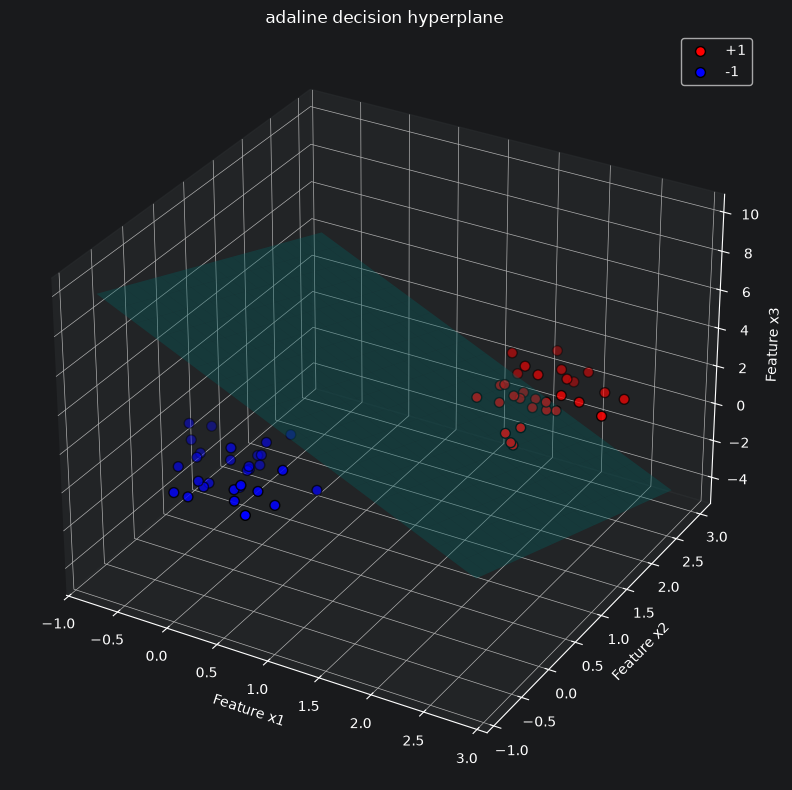

In [55]:
# 3D Visualization of the data and the learned separating hyperplane
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of samples for both classes
ax.scatter(X_pos[:, 0], X_pos[:, 1], X_pos[:, 2], c='red', s=50, label='+1', edgecolors='k')
ax.scatter(X_neg[:, 0], X_neg[:, 1], X_neg[:, 2], c='blue', s=50, label='-1', edgecolors='k')

# Calculate the separating hyperplane: w0 + w1*x1 + w2*x2 + w3*x3 = 0  =>  x3 = -(w0 + w1*x1 + w2*x2) / w3
x1_range = np.linspace(X_3d[:, 0].min() - 0.2, X_3d[:, 0].max() + 0.2, 20)
x2_range = np.linspace(X_3d[:, 1].min() - 0.2, X_3d[:, 1].max() + 0.2, 20)
X1_mesh, X2_mesh = np.meshgrid(x1_range, x2_range)

X3_mesh = -(w_3d[0] + w_3d[1] * X1_mesh + w_3d[2] * X2_mesh) / w_3d[3]
ax.plot_surface(X1_mesh, X2_mesh, X3_mesh, alpha=0.35, color='cyan', edgecolor='none')

ax.set_xlabel('Feature x1')
ax.set_ylabel('Feature x2')
ax.set_zlabel('Feature x3')
ax.set_title('adaline decision hyperplane')
ax.legend()
plt.tight_layout()
plt.show()